# Exercise 5: Linear Regression with Multiple Input Features (Solution)
### (010000) Machine Learning - Spring 2026
### Prof. Cheol Jeong, Sejong University

Use 'Housing price dataset_modified.csv'.

1) Choose two different input features that have negative correlation with 'MEDV'.

2) Perform linear regression using both features to predict 'MEDV'

3) Plot a histogram of residuals.

4) Discuss whether the residuals look approximately Gaussian.

In [7]:
import pandas as pd

df = pd.read_csv("Housing price dataset_modified.csv")

print(df.shape)
df.head()

(506, 12)


,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,36.2


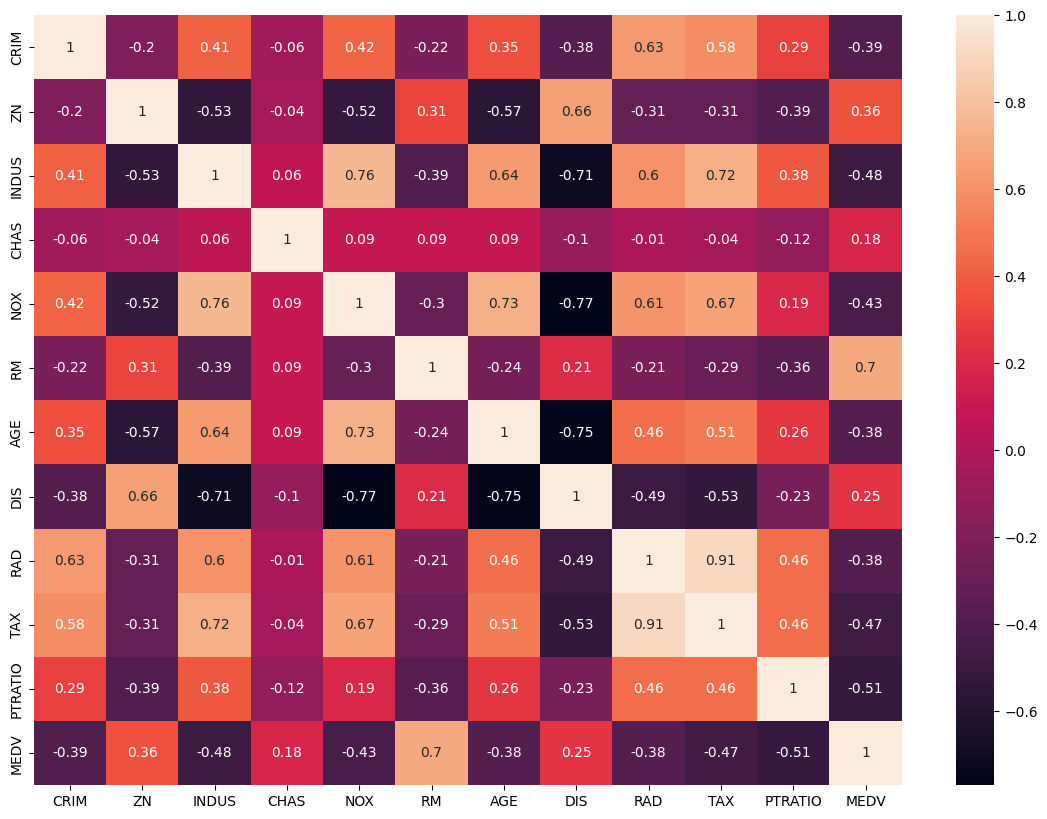

In [8]:
import seaborn as sns
import matplotlib.pyplot as plt

# Generate a correlation matrix
# .round(2) rounds the correlation value to 2 numbers behind comma
correlation_matrix = df.corr().round(2)

# Determine the figure size
plt.figure(figsize=(14,10))

# Plot the correlation matrix
sns.heatmap(data=correlation_matrix, annot=True)
plt.show()

We choose 'CRIM' and 'NOX' because those features have negative correlation values with 'MEDV'. (You can choose other features if those features have negative correlation values with 'MEDV'.)

In [9]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

# Select RM (predictor) and MEDV (target) variables as X and y, respectively
X = df[['CRIM', 'NOX']].values
y = df['MEDV'].values

reg = LinearRegression()
reg.fit(X, y)

print(f"Coefficients: {reg.coef_}")
print(f"reg.intercept_: {reg.intercept_}")

Coefficients: [ -0.27084303 -25.45260814]
reg.intercept_: 37.629939973339944


MSE: 64.548


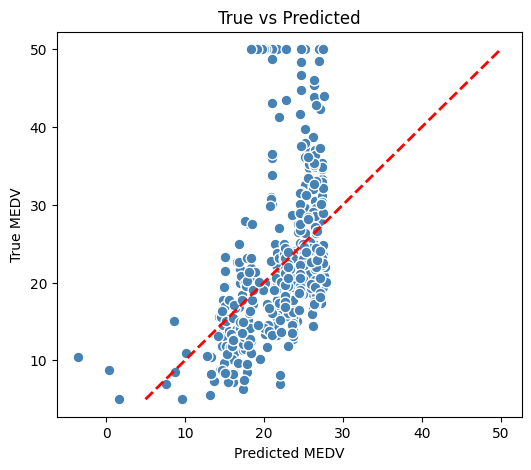

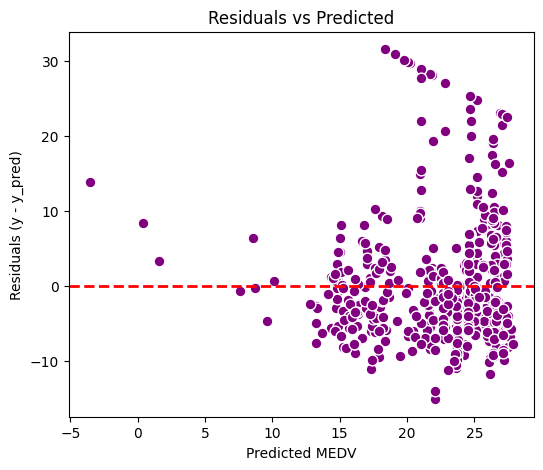

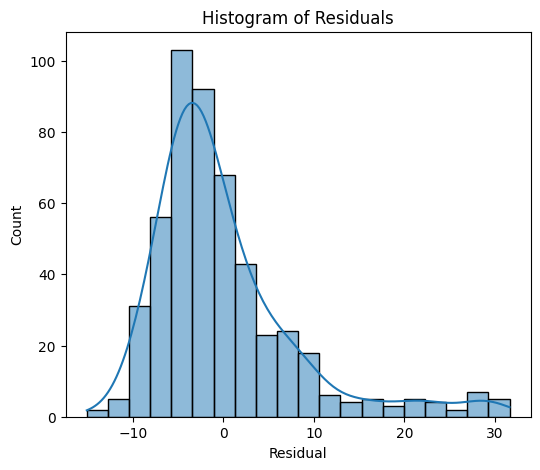

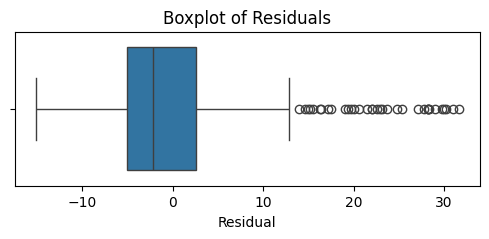

In [10]:
# Predict MEDV using the fitted model
y_pred = reg.predict(X)

# Compute residuals
residuals = y - y_pred

# MSE
mse = mean_squared_error(y, y_pred)
print(f"MSE: {mse:.3f}")

# 1. Predicted vs True
plt.figure(figsize=(6, 5))
plt.scatter(y_pred, y, c='steelblue', edgecolor='white', s=60)
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--', lw=2)
plt.xlabel("Predicted MEDV")
plt.ylabel("True MEDV")

plt.title("True vs Predicted")
plt.show()

# 2. Residuals vs Predicted
plt.figure(figsize=(6, 5))
plt.scatter(y_pred, residuals, c='purple', edgecolor='white', s=60)
plt.axhline(y=0, color='red', linestyle='--', lw=2)
plt.xlabel("Predicted MEDV")
plt.ylabel("Residuals (y - y_pred)")
plt.title("Residuals vs Predicted")
plt.show()

# 3. Histogram of residuals
plt.figure(figsize=(6, 5))
sns.histplot(residuals, bins=20, kde=True)
plt.xlabel("Residual")
plt.title("Histogram of Residuals")
plt.show()

# 4. Residual boxplot
plt.figure(figsize=(6, 2))
sns.boxplot(x=residuals)
plt.xlabel("Residual")
plt.title("Boxplot of Residuals")
plt.show()

It does not look Gaussian overall. However, around the median value, it looks Gaussian.